# Tarefa 3 — Implementação e Comparação de Arquiteturas para Visão Computacional

**Curso de Especialização em Deep Learning · Módulo 3**  
**Autor:** Pedro Serrano

Este notebook compara três famílias de redes neuronais no **mesmo problema de classificação de imagens** (Fashion-MNIST), com as mesmas partições de dados e o mesmo protocolo de treino e avaliação.

| Parte | Arquitetura | Ideia central |
|---|---|---|
| 1 | CNN simples | convoluções e *max-pooling* aprendem padrões locais da imagem |
| 2 | ResNet50 pré-treinada (*transfer learning*) | rede profunda com ligações residuais e pesos aprendidos no ImageNet |
| 3 | RNN (LSTM e GRU) | a imagem é lida linha a linha, como uma sequência |
| 4 | Comparação e análise | acurácia, tempo de treino, tamanho e contextos de utilização |

**Protocolo comum a todos os modelos**
- 54 000 imagens de treino, 6 000 de validação (partição estratificada) e 10 000 de teste, usadas só na avaliação final.
- Paragem antecipada (*early stopping*) sobre a perda de validação, com reposição dos pesos da melhor época.
- As mesmas funções de treino e de avaliação para todos, na mesma máquina, para que os tempos sejam comparáveis.

**Como executar:** *Kernel → Restart & Run All*. Para confirmar em poucos minutos que tudo corre, pôr `MODO_RAPIDO = True` na secção 0.2 (os resultados desse modo não servem para o relatório).

**Tempo de execução:** a ResNet50 domina o tempo total. Na execução guardada neste notebook (CPU com 8 núcleos lógicos, Windows 11), o notebook completo demorou cerca de 90 minutos, dos quais 76 no treino da ResNet50; a CNN, a LSTM e a GRU treinaram em 4 a 5 minutos cada. Com GPU (no Google Colab: *Ambiente de execução → Alterar tipo de ambiente de execução → GPU*) o notebook corre muito mais depressa.

## 0. Preparação do ambiente

### 0.1 Dependências
A célula seguinte instala apenas os pacotes que ainda faltam e verifica a versão do Python.

> **Nota para Windows:** desde a versão 2.11, o TensorFlow nativo no Windows corre **só em CPU** — a placa gráfica NVIDIA não é usada. Para treinar na GPU há duas vias: o **WSL2** (Ubuntu dentro do Windows) com `pip install "tensorflow[and-cuda]"`, ou o **Google Colab**. Se a instalação do TensorFlow falhar com erros de caminho demasiado longo, é preciso ativar os caminhos longos do Windows (`LongPathsEnabled`).

> **Ambiente:** o ficheiro `requirements.txt` que acompanha o notebook tem as versões exatas usadas nesta execução e as instruções de instalação. Se, no Windows, o `import tensorflow` falhar com *DLL load failed while importing _pywrap_tensorflow_internal*, a causa habitual é um `pyzmq` antigo (versão 25 ou anterior) no ambiente do kernel, que carrega uma versão antiga do `msvcp140.dll` antes do TensorFlow: `pip install -U pyzmq` e reiniciar o kernel.

In [1]:
# =============================================================================
# 0.1  Dependências: instala apenas os pacotes que ainda faltam
# =============================================================================
import importlib.util
import platform
import struct
import subprocess
import sys

# (requisito do pip, módulo importado no código)
DEPENDENCIAS = [
    ("tensorflow>=2.16", "tensorflow"),   # o TensorFlow 2.16+ já inclui o Keras 3
    ("numpy>=1.26", "numpy"),
    ("pandas>=2.0", "pandas"),
    ("matplotlib>=3.7", "matplotlib"),
    ("scikit-learn>=1.3", "sklearn"),
]
# Versões exatas com que o notebook foi testado (para reprodutibilidade total):
#   pip install tensorflow==2.21.0 keras==3.15.1 numpy==2.4.4 pandas==3.0.2 matplotlib==3.10.8 scikit-learn==1.8.0

em_falta = [requisito for requisito, modulo in DEPENDENCIAS if importlib.util.find_spec(modulo) is None]
if em_falta:
    print("A instalar:", ", ".join(em_falta))
    subprocess.check_call([sys.executable, "-m", "pip", "install", "--quiet", *em_falta])
    print("Instalação concluída. Se o import do TensorFlow falhar a seguir, reiniciar o kernel.")
else:
    print("Todas as dependências já estão instaladas.")

# O TensorFlow só existe para Python de 64 bits e exige Python 3.10 ou superior
bits = struct.calcsize("P") * 8
print(f"Python {platform.python_version()} ({bits} bits) | {platform.system()} {platform.release()}")
if bits != 64:
    print("⚠ O TensorFlow exige Python de 64 bits.")
if sys.version_info < (3, 10):
    print("⚠ O TensorFlow atual exige Python 3.10 ou superior.")

Todas as dependências já estão instaladas.
Python 3.12.6 (64 bits) | Windows 11


### 0.2 Importações e configuração
As sementes aleatórias ficam fixas para que os resultados sejam reprodutíveis; as pequenas diferenças que restam entre execuções vêm do paralelismo do hardware. `MODO_RAPIDO = True` treina com subconjuntos pequenos e uma época por modelo — serve apenas para confirmar que o código corre do princípio ao fim.

In [2]:
# =============================================================================
# 0.2  Importações, sementes e configuração geral
# =============================================================================
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"   # esconde as mensagens informativas do TensorFlow

import json
import platform
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf
import keras
from keras import layers
from IPython.display import display
from matplotlib.ticker import MaxNLocator
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.model_selection import train_test_split

if int(keras.__version__.split(".")[0]) < 3:
    raise RuntimeError("Este notebook precisa do Keras 3 (TensorFlow 2.16 ou superior): "
                       "pip install -U tensorflow")

tf.get_logger().setLevel("ERROR")   # esconde avisos inofensivos de "retracing" do TensorFlow
INICIO_NOTEBOOK = time.perf_counter()
SEMENTE = 42
keras.utils.set_random_seed(SEMENTE)   # fixa as sementes do Python, do NumPy e do TensorFlow

# True: subconjuntos pequenos e 1 época por modelo, só para testar o código de ponta a ponta.
# False: execução completa, a que produz os resultados do relatório.
MODO_RAPIDO = False

EPOCAS_MAX = 1 if MODO_RAPIDO else 20   # CNN, LSTM e GRU (a paragem antecipada decide quando parar)
PASTA = "resultados_tarefa3"            # figuras, tabela e resultados em JSON
os.makedirs(PASTA, exist_ok=True)

gpus = tf.config.list_physical_devices("GPU")
if gpus:
    DISPOSITIVO = "GPU " + tf.config.experimental.get_device_details(gpus[0]).get("device_name", "")
else:
    n_nucleos = os.cpu_count() or 1
    DISPOSITIVO = f"CPU ({n_nucleos} {'núcleo lógico' if n_nucleos == 1 else 'núcleos lógicos'})"

print(f"TensorFlow {tf.__version__} | Keras {keras.__version__} | NumPy {np.__version__} | pandas {pd.__version__}")
print("Treino em:", DISPOSITIVO)
if MODO_RAPIDO:
    print("⚠ MODO_RAPIDO ativo: os resultados não são representativos.")

# Estilo comum a todos os gráficos
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 150,
    "axes.grid": True, "grid.alpha": 0.3,
    "axes.spines.top": False, "axes.spines.right": False,
})
CORES = {"CNN": "#1f77b4", "ResNet50": "#d62728", "LSTM": "#2ca02c", "GRU": "#9467bd"}

TensorFlow 2.21.0 | Keras 3.15.1 | NumPy 2.4.4 | pandas 3.0.2
Treino em: CPU (8 núcleos lógicos)


### 0.3 Funções auxiliares
Todos os modelos passam pelas mesmas funções — é isto que torna a comparação da Parte 4 justa:
- `treinar()` treina com paragem antecipada e mede o tempo total e o tempo de cada época;
- `avaliar()` calcula a acurácia e a perda no teste, o intervalo de confiança da acurácia, o tempo de inferência, o número de parâmetros e o tamanho dos pesos;
- `grafico_treino()` e `grafico_confusao()` desenham as curvas de treino e a matriz de confusão, e guardam as figuras na pasta de resultados.

In [3]:
# =============================================================================
# 0.3  Funções auxiliares, partilhadas por todos os modelos
# =============================================================================
RESULTADOS = {}   # métricas finais de cada modelo (tabela da Parte 4)
PREVISOES = {}    # classes previstas no conjunto de teste
HISTORICOS = {}   # curvas de treino


class TempoPorEpoca(keras.callbacks.Callback):
    """Regista a duração, em segundos, de cada época de treino."""

    def on_train_begin(self, logs=None):
        self.tempos = []

    def on_epoch_begin(self, epoch, logs=None):
        self._inicio = time.perf_counter()

    def on_epoch_end(self, epoch, logs=None):
        self.tempos.append(time.perf_counter() - self._inicio)


def treinar(modelo, x_treino, y_treino, x_val, y_val, epocas, lote, paciencia=3):
    """Treina com paragem antecipada e devolve (histórico, tempo total em s, tempos por época).

    A paragem antecipada vigia a perda de validação: se não melhorar durante `paciencia`
    épocas seguidas, o treino para. No fim, o modelo fica com os pesos da melhor época.
    """
    cronometro = TempoPorEpoca()
    paragem = keras.callbacks.EarlyStopping(monitor="val_loss", patience=paciencia,
                                            restore_best_weights=True)
    inicio = time.perf_counter()
    historico = modelo.fit(x_treino, y_treino, validation_data=(x_val, y_val),
                           epochs=epocas, batch_size=lote,
                           callbacks=[cronometro, paragem], verbose=2)
    return historico.history, time.perf_counter() - inicio, cronometro.tempos


def avaliar(nome, modelo, x_teste, y_teste, historico, tempo_treino, tempos_epoca):
    """Avalia no conjunto de teste e regista as métricas da tabela comparativa."""
    # Tempo de inferência: uma passagem de aquecimento (constrói o grafo) e depois a medição
    modelo.predict(x_teste[:256], batch_size=256, verbose=0)
    inicio = time.perf_counter()
    probabilidades = modelo.predict(x_teste, batch_size=256, verbose=0)
    ms_por_imagem = (time.perf_counter() - inicio) / len(x_teste) * 1000

    previsoes = probabilidades.argmax(axis=1)
    acuracia = float(np.mean(previsoes == y_teste))
    # Entropia cruzada calculada a partir das probabilidades (evita uma segunda passagem pelo teste)
    p_classe_certa = probabilidades[np.arange(len(y_teste)), y_teste]
    perda = float(-np.mean(np.log(np.clip(p_classe_certa, 1e-7, 1.0))))
    # Intervalo de confiança a 95 % da acurácia (aproximação normal da binomial)
    ic95 = 1.96 * np.sqrt(acuracia * (1 - acuracia) / len(y_teste))

    # Tamanho do modelo: memória ocupada pelos pesos (4 bytes por parâmetro em float32), que é o que
    # ocupa o modelo guardado para produção. Atenção: no Keras 3, o ficheiro de model.save_weights()
    # inclui também o estado do otimizador (no Adam, mais duas cópias dos pesos treináveis) e fica
    # cerca de 3 vezes maior, por isso o tamanho é calculado diretamente a partir dos pesos.
    tamanho_mb = float(sum(np.prod(p.shape) * np.dtype(p.dtype).itemsize for p in modelo.weights) / 1024**2)

    RESULTADOS[nome] = {
        "Acurácia (teste)": acuracia,
        "IC 95 % (±)": float(ic95),
        "Perda (teste)": perda,
        "Épocas": len(historico["loss"]),
        "Tempo de treino (s)": tempo_treino,
        "Tempo médio por época (s)": float(np.mean(tempos_epoca)),
        "Parâmetros": int(modelo.count_params()),
        "Parâmetros treináveis": int(sum(np.prod(p.shape) for p in modelo.trainable_weights)),
        "Tamanho dos pesos (MB)": tamanho_mb,
        "Inferência (ms/imagem)": ms_por_imagem,
    }
    PREVISOES[nome] = previsoes
    HISTORICOS[nome] = historico
    print(f"{nome}: acurácia no teste {acuracia:.2%} (± {ic95:.2%}) | perda {perda:.4f} | "
          f"{modelo.count_params():,} parâmetros | {tamanho_mb:.2f} MB | "
          f"{ms_por_imagem:.3f} ms por imagem")
    return previsoes


def grafico_treino(historico, titulo, ficheiro, fim_fase_a=None):
    """Curvas de perda e de acurácia (treino e validação), com a melhor época assinalada."""
    epocas = np.arange(1, len(historico["loss"]) + 1)
    melhor = int(np.argmin(historico["val_loss"])) + 1
    fig, eixos = plt.subplots(1, 2, figsize=(12, 4.2))
    for eixo, chave, rotulo in [(eixos[0], "loss", "Perda (entropia cruzada)"),
                                (eixos[1], "accuracy", "Acurácia")]:
        if fim_fase_a is not None:   # fundo cinzento: fase A da ResNet (base congelada)
            eixo.axvspan(0.5, fim_fase_a + 0.5, color="0.5", alpha=0.12, label="Fase A (base congelada)")
        eixo.plot(epocas, historico[chave], "o-", label="Treino")
        eixo.plot(epocas, historico["val_" + chave], "s-", label="Validação")
        eixo.axvline(melhor, color="tab:red", ls="--", lw=1, label=f"Melhor época ({melhor})")
        eixo.set_xlabel("Época")
        eixo.set_ylabel(rotulo)
        eixo.set_xlim(0.5, len(epocas) + 0.5)
        eixo.xaxis.set_major_locator(MaxNLocator(integer=True))
        eixo.legend()
    fig.suptitle(titulo, fontweight="bold")
    fig.tight_layout()
    fig.savefig(os.path.join(PASTA, ficheiro), bbox_inches="tight")
    plt.show()


def grafico_confusao(y_real, y_previsto, titulo, ficheiro):
    """Matriz de confusão normalizada por linha: % de cada classe real atribuída a cada classe prevista."""
    matriz = confusion_matrix(y_real, y_previsto, labels=range(10), normalize="true") * 100
    fig, eixo = plt.subplots(figsize=(7.6, 6.4))
    imagem = eixo.imshow(matriz, cmap="Blues", vmin=0, vmax=100)
    eixo.set_xticks(range(10), CLASSES, rotation=45, ha="right")
    eixo.set_yticks(range(10), CLASSES)
    for i in range(10):
        for j in range(10):
            if matriz[i, j] >= 0.5:
                eixo.text(j, i, f"{matriz[i, j]:.0f}", ha="center", va="center", fontsize=8,
                          color="white" if matriz[i, j] > 60 else "black")
    eixo.set_xlabel("Classe prevista")
    eixo.set_ylabel("Classe real")
    eixo.set_title(titulo, fontweight="bold")
    eixo.grid(False)
    fig.colorbar(imagem, ax=eixo, fraction=0.046, pad=0.04, label="% da classe real")
    fig.tight_layout()
    fig.savefig(os.path.join(PASTA, ficheiro), bbox_inches="tight")
    plt.show()

## 1. Dados: Fashion-MNIST

O Fashion-MNIST tem 70 000 imagens de 28×28 píxeis em tons de cinzento, de 10 classes de vestuário e calçado (7 000 por classe).

**Porquê este dataset e não o MNIST ou o CIFAR-10?**
- No **MNIST** (dígitos manuscritos), praticamente qualquer arquitetura chega aos 98–99 % — as diferenças entre modelos ficariam escondidas no ruído.
- O **CIFAR-10** (fotografias 32×32 a cores) é bastante mais difícil: as redes pequenas precisam de muito mais épocas e de aumento de dados para chegarem a resultados razoáveis, o que multiplica o tempo de treino.
- O **Fashion-MNIST** fica no meio: é difícil o suficiente para separar as arquiteturas (há classes muito parecidas, como camisa, T-shirt e camisola) e leve o suficiente para treinar os quatro modelos no mesmo notebook. É também o dataset da Tarefa 2, o que permite comparar com a MLP aí treinada.

In [4]:
# =============================================================================
# 1.1  Carregar e inspecionar o Fashion-MNIST
# =============================================================================
CLASSES = ["T-shirt/top", "Calças", "Camisola", "Vestido", "Casaco",
           "Sandália", "Camisa", "Sapatilha", "Mala", "Botim"]

(x_treino_total, y_treino_total), (x_teste, y_teste) = keras.datasets.fashion_mnist.load_data()
print("Treino (total):", x_treino_total.shape, "| Teste:", x_teste.shape)
print(f"Píxeis: {x_treino_total.dtype}, de {x_treino_total.min()} a {x_treino_total.max()}")

contagens = pd.DataFrame({"Treino": np.bincount(y_treino_total), "Teste": np.bincount(y_teste)},
                         index=CLASSES)
display(contagens.T)   # 6 000 + 1 000 imagens por classe: o dataset está equilibrado

Treino (total): (60000, 28, 28) | Teste: (10000, 28, 28)
Píxeis: uint8, de 0 a 255


,T-shirt/top,Calças,Camisola,Vestido,Casaco,Sandália,Camisa,Sapatilha,Mala,Botim
Treino,6000,6000,6000,6000,6000,6000,6000,6000,6000,6000
Teste,1000,1000,1000,1000,1000,1000,1000,1000,1000,1000


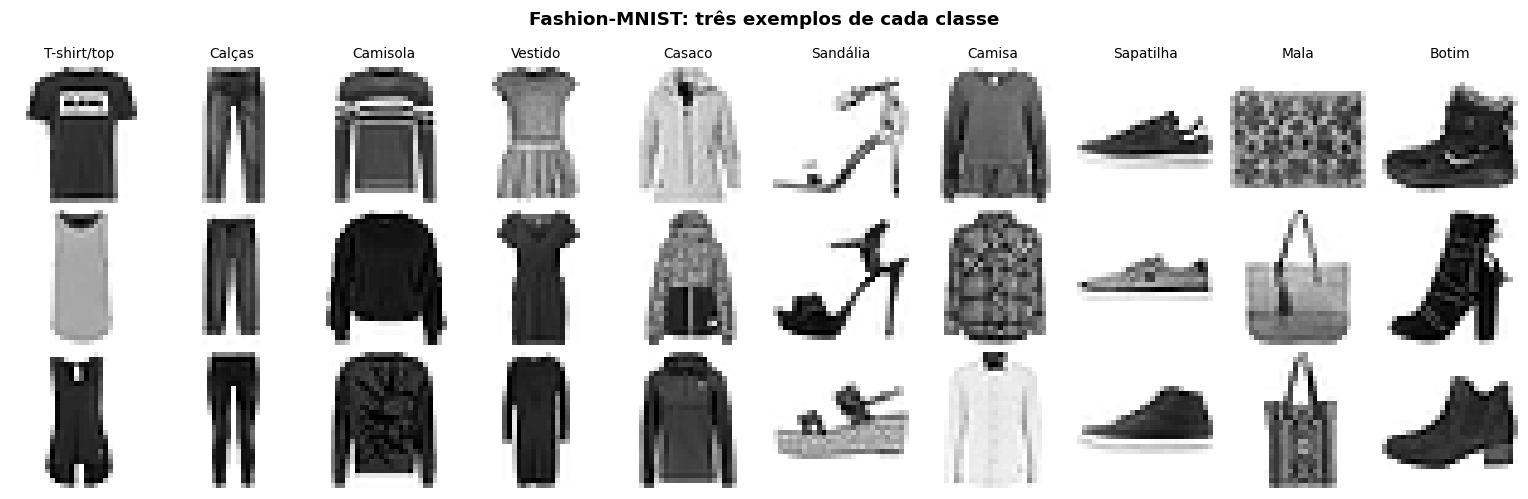

In [5]:
# Três exemplos de cada classe
fig, eixos = plt.subplots(3, 10, figsize=(14, 4.6))
for classe in range(10):
    for linha, i in enumerate(np.flatnonzero(y_treino_total == classe)[:3]):
        eixos[linha, classe].imshow(x_treino_total[i], cmap="gray_r")
        eixos[linha, classe].axis("off")
        if linha == 0:
            eixos[linha, classe].set_title(CLASSES[classe], fontsize=9)
fig.suptitle("Fashion-MNIST: três exemplos de cada classe", fontweight="bold")
fig.tight_layout()
fig.savefig(os.path.join(PASTA, "01_exemplos.png"), bbox_inches="tight")
plt.show()

### 1.2 Partição e normalização
- **Validação:** 6 000 imagens (10 % do treino), com estratificação, para que cada classe mantenha a mesma proporção. Serve para a paragem antecipada e para acompanhar o sobreajuste.
- **Teste:** as 10 000 imagens oficiais, usadas uma única vez por modelo, no fim.
- **Normalização:** os píxeis passam de 0–255 para 0–1 (`float32`). A CNN e a ResNet recebem imagens com um canal, `(28, 28, 1)`; a RNN recebe as mesmas imagens sem o canal, `(28, 28)`.

In [6]:
# =============================================================================
# 1.2  Partição treino/validação e normalização
# =============================================================================
x_treino, x_val, y_treino, y_val = train_test_split(
    x_treino_total, y_treino_total, test_size=6000, stratify=y_treino_total, random_state=SEMENTE)


def preparar(x):
    """uint8 (N, 28, 28) -> float32 em [0, 1] com um canal: (N, 28, 28, 1)."""
    return (x.astype("float32") / 255.0)[..., np.newaxis]


X_TREINO, X_VAL, X_TESTE = preparar(x_treino), preparar(x_val), preparar(x_teste)

if MODO_RAPIDO:   # subconjuntos pequenos, só para testar o código
    X_TREINO, y_treino = X_TREINO[:2000], y_treino[:2000]
    X_VAL, y_val = X_VAL[:500], y_val[:500]
    X_TESTE, y_teste = X_TESTE[:1000], y_teste[:1000]

print("Treino:", X_TREINO.shape, "| Validação:", X_VAL.shape, "| Teste:", X_TESTE.shape)
print("Proporção de cada classe na validação:", np.round(np.bincount(y_val) / len(y_val), 3))

Treino: (54000, 28, 28, 1) | Validação: (6000, 28, 28, 1) | Teste: (10000, 28, 28, 1)
Proporção de cada classe na validação: [0.1 0.1 0.1 0.1 0.1 0.1 0.1 0.1 0.1 0.1]


## 2. Parte 1 — Rede Convolucional (CNN)

Uma CNN aproveita a estrutura espacial da imagem:
- **Convolução** — cada filtro 3×3 percorre a imagem e responde a um padrão local (uma aresta, uma curva). Os mesmos pesos são usados em todas as posições (*partilha de pesos*), o que reduz muito o número de parâmetros e faz com que um padrão seja reconhecido onde quer que apareça.
- **Max-pooling** — reduz a resolução para metade, guardando o valor máximo de cada janela 2×2. Torna a rede mais tolerante a pequenas deslocações e alarga o campo recetivo das camadas seguintes.
- **Camadas densas** — combinam as características extraídas; a **Softmax** final converte-as em probabilidades para as 10 classes.

**Arquitetura** — cumpre o enunciado: duas camadas convolucionais, cada uma seguida de *max-pooling*, e camada densa final com Softmax:

`Conv2D(32, 3×3, ReLU) → MaxPool(2×2) → Conv2D(64, 3×3, ReLU) → MaxPool(2×2) → Flatten → Dropout(0,3) → Dense(128, ReLU) → Dropout(0,3) → Dense(10, Softmax)`

O *dropout* desliga aleatoriamente 30 % dos neurónios durante o treino, para reduzir o sobreajuste. Treino com o otimizador Adam (taxa de aprendizagem 0,001), lotes de 128 imagens e até 20 épocas, com paragem antecipada ao fim de 3 épocas sem melhoria.

In [7]:
# =============================================================================
# 2.1  Arquitetura da CNN
# =============================================================================
def criar_cnn():
    return keras.Sequential([
        keras.Input(shape=(28, 28, 1), name="imagem"),
        # Bloco 1: 32 filtros 3x3 detetam padrões simples (arestas, contornos)
        layers.Conv2D(32, 3, padding="same", activation="relu", name="conv1"),
        layers.MaxPooling2D(2, name="pool1"),                   # 28x28 -> 14x14
        # Bloco 2: 64 filtros combinam os padrões anteriores em formas mais complexas
        layers.Conv2D(64, 3, padding="same", activation="relu", name="conv2"),
        layers.MaxPooling2D(2, name="pool2"),                   # 14x14 -> 7x7
        # Classificador
        layers.Flatten(name="achatar"),                          # 7x7x64 -> 3 136 valores
        layers.Dropout(0.3, name="dropout1"),
        layers.Dense(128, activation="relu", name="densa"),
        layers.Dropout(0.3, name="dropout2"),
        layers.Dense(10, activation="softmax", name="saida"),   # probabilidades das 10 classes
    ], name="CNN")


cnn = criar_cnn()
cnn.compile(optimizer=keras.optimizers.Adam(1e-3), loss="sparse_categorical_crossentropy",
            metrics=["accuracy"])
cnn.summary()

Model: "CNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1 (Conv2D)                  │ (None, 28, 28, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool1 (MaxPooling2D)            │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2 (Conv2D)                  │ (None, 14, 14, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool2 (MaxPooling2D)            │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ achatar (Flatten)               │ (None, 3136)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout1 (Dropout)              │ (None, 3136)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ densa (Dense)                   │ (None, 128)            │       401,536 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout2 (Dropout)              │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ saida (Dense)                   │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 421,642 (1.61 MB)

 Trainable params: 421,642 (1.61 MB)

 Non-trainable params: 0 (0.00 B)

In [8]:
# 2.2 Treino
hist_cnn, tempo_cnn, tempos_cnn = treinar(cnn, X_TREINO, y_treino, X_VAL, y_val,
                                          epocas=EPOCAS_MAX, lote=128)
print(f"\nTreino da CNN: {tempo_cnn:.0f} s em {len(tempos_cnn)} épocas "
      f"({np.mean(tempos_cnn):.1f} s por época)")

Epoch 1/20


422/422 - 15s - 35ms/step - accuracy: 0.8025 - loss: 0.5505 - val_accuracy: 0.8805 - val_loss: 0.3337


Epoch 2/20


422/422 - 15s - 35ms/step - accuracy: 0.8730 - loss: 0.3536 - val_accuracy: 0.8915 - val_loss: 0.2916


Epoch 3/20


...

Epoch 18/20


422/422 - 16s - 37ms/step - accuracy: 0.9493 - loss: 0.1356 - val_accuracy: 0.9325 - val_loss: 0.1885


Epoch 19/20


422/422 - 15s - 36ms/step - accuracy: 0.9510 - loss: 0.1277 - val_accuracy: 0.9303 - val_loss: 0.1903



Treino da CNN: 289 s em 19 épocas (15.2 s por época)


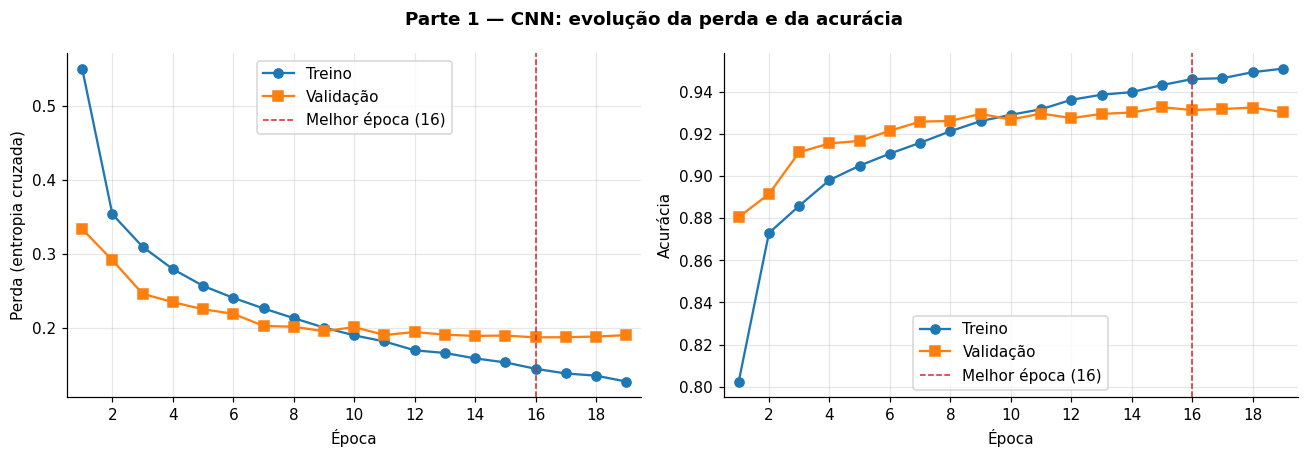

Na melhor época (16): acurácia de treino 94.60%, de validação 93.13% (diferença de 1.47 p.p.)


In [9]:
# 2.3 Evolução da perda e da acurácia
grafico_treino(hist_cnn, "Parte 1 — CNN: evolução da perda e da acurácia", "02_cnn_curvas.png")

melhor = int(np.argmin(hist_cnn["val_loss"]))
folga = (hist_cnn["accuracy"][melhor] - hist_cnn["val_accuracy"][melhor]) * 100
print(f"Na melhor época ({melhor + 1}): acurácia de treino {hist_cnn['accuracy'][melhor]:.2%}, "
      f"de validação {hist_cnn['val_accuracy'][melhor]:.2%} (diferença de {folga:.2f} p.p.)")

CNN: acurácia no teste 92.62% (± 0.51%) | perda 0.2180 | 421,642 parâmetros | 1.61 MB | 0.099 ms por imagem

              precision    recall  f1-score   support

 T-shirt/top      0.843     0.906     0.873      1000
      Calças      0.992     0.986     0.989      1000
    Camisola      0.892     0.888     0.890      1000
     Vestido      0.907     0.958     0.932      1000
      Casaco      0.877     0.894     0.886      1000
    Sandália      0.991     0.985     0.988      1000
      Camisa      0.827     0.714     0.767      1000
   Sapatilha      0.965     0.975     0.970      1000
        Mala      0.991     0.983     0.987      1000
       Botim      0.971     0.973     0.972      1000

    accuracy                          0.926     10000
   macro avg      0.926     0.926     0.925     10000
weighted avg      0.926     0.926     0.925     10000



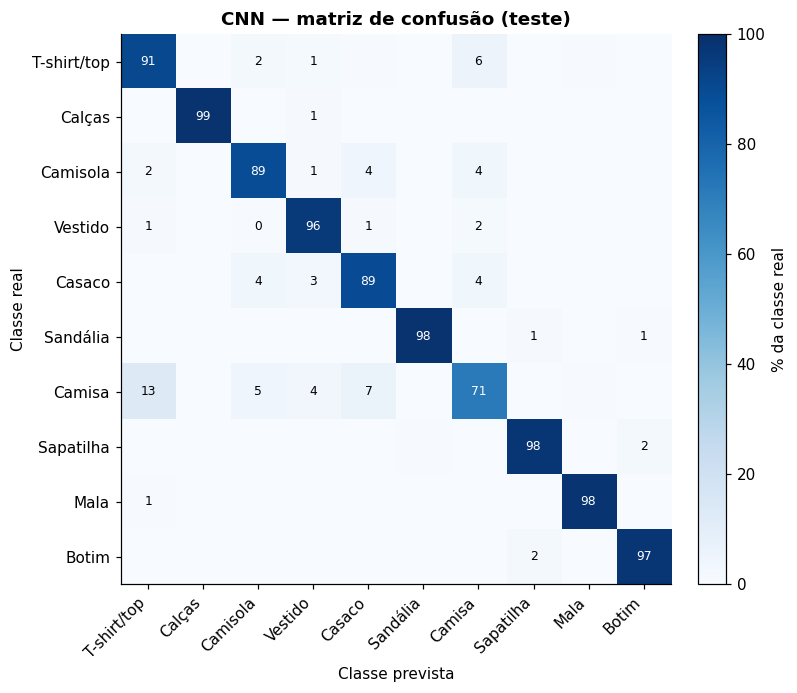

In [10]:
# 2.4 Avaliação no conjunto de teste
prev_cnn = avaliar("CNN", cnn, X_TESTE, y_teste, hist_cnn, tempo_cnn, tempos_cnn)
print()
print(classification_report(y_teste, prev_cnn, target_names=CLASSES, digits=3, zero_division=0))
grafico_confusao(y_teste, prev_cnn, "CNN — matriz de confusão (teste)", "03_cnn_confusao.png")

### 2.5 O que a CNN "vê"
Os mapas de ativação mostram a resposta de alguns filtros a uma imagem de teste. Na primeira camada, os filtros realçam arestas e zonas claras/escuras da peça; na segunda, com metade da resolução, as respostas já são mais abstratas e localizadas — combinações de padrões da camada anterior.

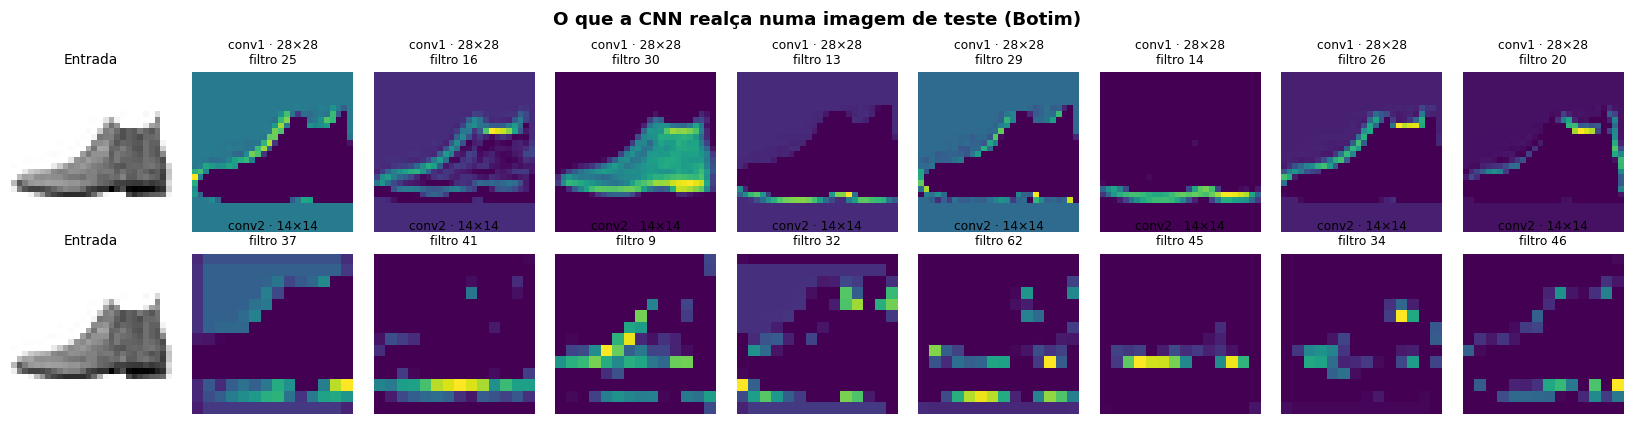

In [11]:
# 2.5 Mapas de ativação das duas camadas convolucionais
extrator = keras.Model(inputs=cnn.inputs,
                       outputs=[cnn.get_layer("conv1").output, cnn.get_layer("conv2").output])
indice = int(np.flatnonzero(y_teste == 9)[0])     # primeiro botim do conjunto de teste
mapas_conv1, mapas_conv2 = extrator.predict(X_TESTE[indice:indice + 1], verbose=0)

fig, eixos = plt.subplots(2, 9, figsize=(15, 3.9))
for linha, (mapas, nome) in enumerate([(mapas_conv1, "conv1 · 28×28"), (mapas_conv2, "conv2 · 14×14")]):
    eixos[linha, 0].imshow(X_TESTE[indice, ..., 0], cmap="gray_r")
    eixos[linha, 0].set_title("Entrada", fontsize=9)
    # os 8 filtros com maior ativação média nesta imagem
    for coluna, filtro in enumerate(np.argsort(mapas[0].mean(axis=(0, 1)))[::-1][:8], start=1):
        eixos[linha, coluna].imshow(mapas[0, ..., filtro], cmap="viridis")
        eixos[linha, coluna].set_title(f"{nome}\nfiltro {filtro}", fontsize=8)
    for eixo in eixos[linha]:
        eixo.axis("off")
fig.suptitle(f"O que a CNN realça numa imagem de teste ({CLASSES[y_teste[indice]]})", fontweight="bold")
fig.tight_layout()
fig.savefig(os.path.join(PASTA, "04_cnn_mapas_ativacao.png"), bbox_inches="tight")
plt.show()

## 3. Parte 2 — Rede Residual (ResNet50 com *transfer learning*)

**Ligações residuais.** Em redes muito profundas, acrescentar camadas chega a *piorar* o erro de treino (o problema da degradação), porque o sinal e o gradiente se diluem ao atravessar dezenas de camadas. A ResNet resolve isto com atalhos: cada bloco aprende apenas uma correção `F(x)` e soma-a à própria entrada, `y = F(x) + x`. Se a correção não for útil, basta aprender `F(x) ≈ 0`, e o gradiente tem sempre um caminho direto até às primeiras camadas.

**ResNet50.** 50 camadas com pesos: uma convolução inicial, 16 blocos *bottleneck* (1×1 → 3×3 → 1×1) distribuídos por quatro estágios de 3, 4, 6 e 3 blocos, e a camada de classificação. Uso os pesos treinados no **ImageNet** (1,2 milhões de fotografias, 1 000 classes), disponíveis em `keras.applications`, sem a camada de classificação original.

**Adaptações ao Fashion-MNIST**
1. **Canais:** a rede espera imagens RGB, por isso o canal cinzento é replicado três vezes.
2. **Resolução:** a ResNet50 do Keras exige pelo menos 32×32; as imagens são redimensionadas de 28×28 para 32×32 *dentro do modelo*. Redimensionar o dataset inteiro para 224×224 antes do treino ocuparia ≈ 32 GB de memória (54 000 × 224 × 224 × 3 × 4 bytes) e tornaria cada época ≈ 49 vezes mais cara.
3. **Pré-processamento:** o mesmo do treino original no ImageNet — escala 0–255 e subtração da média de cada canal —, equivalente a `keras.applications.resnet50.preprocess_input` (verificado na secção 3.2).

**Treino em duas fases**
- **Fase A — extração de características:** a base convolucional fica congelada e só a nova cabeça (Dropout + Dense Softmax) é treinada. Assim, os gradientes grandes de uma cabeça ainda aleatória não estragam os pesos pré-treinados.
- **Fase B — afinação (*fine-tuning*):** a base é descongelada e o treino continua com uma taxa de aprendizagem 10 vezes menor (0,0001), para ajustar os filtros do ImageNet às peças de roupa sem os destruir. As camadas *BatchNormalization* ficam congeladas e em modo de inferência, para não trocarem as estatísticas do ImageNet pelas de lotes pequenos.

Em CPU, a fase B é a parte mais lenta do notebook. `INICIO_AFINACAO = "conv5_block1"` (secção 3.4) afina só o último estágio e reduz o tempo por época para cerca de metade. Na execução guardada, com a base inteira, cada época da fase B demorou entre 13 e 16 minutos (72 minutos no total), contra cerca de 2 minutos na fase A.

In [12]:
# =============================================================================
# 3.1  ResNet50 pré-treinada no ImageNet + nova cabeça de classificação
# =============================================================================
TAMANHO_RESNET = 32   # mínimo aceite pela ResNet50 do Keras; com GPU pode experimentar-se 64 ou 96
MEDIAS_IMAGENET = [103.939, 116.779, 123.68]   # média de cada canal (ordem BGR) no treino original


def criar_resnet(tamanho=TAMANHO_RESNET):
    """Devolve (modelo completo, base ResNet50). A base começa congelada (fase A)."""
    entrada = keras.Input(shape=(28, 28, 1), name="imagem")
    # (1) 28x28 -> tamanho x tamanho, dentro do modelo: as imagens ampliadas nunca ocupam memória
    x = layers.Resizing(tamanho, tamanho, name="redimensionar")(entrada)
    # (2) 1 canal -> 3 canais, porque a rede foi treinada com imagens RGB
    x = layers.Concatenate(name="cinzento_para_rgb")([x, x, x])
    # (3) pré-processamento do ImageNet ("caffe"): escala 0-255 e subtração da média de cada canal
    x = layers.Rescaling(255.0, name="escala_0_255")(x)
    x = layers.Normalization(mean=MEDIAS_IMAGENET, variance=[1.0, 1.0, 1.0], name="subtrair_medias")(x)
    # (4) base convolucional pré-treinada, sem a classificação original (1 000 classes);
    #     pooling="avg" faz a média global de cada mapa de características -> vetor de 2 048 valores
    base = keras.applications.ResNet50(include_top=False, weights="imagenet",
                                       input_shape=(tamanho, tamanho, 3), pooling="avg")
    base.trainable = False
    x = base(x, training=False)   # training=False: BatchNormalization sempre em modo de inferência
    # (5) nova cabeça para as 10 classes do Fashion-MNIST
    x = layers.Dropout(0.3, name="dropout")(x)
    saida = layers.Dense(10, activation="softmax", name="saida")(x)
    return keras.Model(entrada, saida, name="ResNet50_transfer_learning"), base


resnet, base_resnet = criar_resnet()
resnet.compile(optimizer=keras.optimizers.Adam(1e-3), loss="sparse_categorical_crossentropy",
               metrics=["accuracy"])
resnet.summary()

n_conv = sum(isinstance(camada, layers.Conv2D) for camada in base_resnet.layers)
print(f"Base ResNet50: {len(base_resnet.layers)} camadas Keras, das quais {n_conv} convolucionais "
      f"(49 no caminho principal + 4 projeções nos atalhos); {base_resnet.count_params():,} parâmetros")

Model: "ResNet50_transfer_learning"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ imagem (InputLayer) │ (None, 28, 28, 1) │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ redimensionar       │ (None, 32, 32, 1) │          0 │ imagem[0][0]      │
│ (Resizing)          │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ cinzento_para_rgb   │ (None, 32, 32, 3) │          0 │ redimensionar[0]… │
│ (Concatenate)       │                   │            │ redimensionar[0]… │
│                     │                   │            │ redimensionar[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ escala_0_255        │ (None, 32, 32, 3) │          0 │ cinzento_para_rg… │
│ (Rescaling)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ subtrair_medias     │ (None, 32, 32, 3) │          0 │ escala_0_255[0][… │
│ (Normalization)     │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ resnet50            │ (None, 2048)      │ 23,587,712 │ subtrair_medias[… │
│ (Functional)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 2048)      │          0 │ resnet50[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ saida (Dense)       │ (None, 10)        │     20,490 │ dropout[0][0]     │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 23,608,202 (90.06 MB)

 Trainable params: 20,490 (80.04 KB)

 Non-trainable params: 23,587,712 (89.98 MB)

Base ResNet50: 176 camadas Keras, das quais 53 convolucionais (49 no caminho principal + 4 projeções nos atalhos); 23,587,712 parâmetros


In [13]:
# 3.2 Verificação: o pré-processamento dentro do modelo é igual ao preprocess_input oficial
from keras.applications.resnet50 import preprocess_input

pre_modelo = keras.Model(resnet.input, resnet.get_layer("subtrair_medias").output)
amostra = X_TREINO[:32]
nosso = pre_modelo.predict(amostra, verbose=0)
ampliada = keras.ops.convert_to_numpy(keras.ops.image.resize(amostra, (TAMANHO_RESNET, TAMANHO_RESNET)))
oficial = preprocess_input(np.repeat(ampliada, 3, axis=-1) * 255.0)
diferenca = float(np.abs(nosso - oficial).max())
print(f"Diferença máxima entre as duas versões: {diferenca:.1e} →",
      "equivalentes ✔" if diferenca < 1e-3 else "DIFERENTES ✘ (rever o pré-processamento)")

Diferença máxima entre as duas versões: 0.0e+00 → equivalentes ✔


In [14]:
# 3.3 Fase A — base congelada: só a nova cabeça aprende
EPOCAS_FASE_A = 1 if MODO_RAPIDO else 2
print(f"Parâmetros treinados na fase A: {sum(np.prod(p.shape) for p in resnet.trainable_weights):,}")
hist_a, tempo_a, tempos_a = treinar(resnet, X_TREINO, y_treino, X_VAL, y_val,
                                    epocas=EPOCAS_FASE_A, lote=64)
print(f"\nFase A: {tempo_a:.0f} s")

Parâmetros treinados na fase A: 20,490


Epoch 1/2


844/844 - 119s - 141ms/step - accuracy: 0.7535 - loss: 0.8801 - val_accuracy: 0.8258 - val_loss: 0.5159


Epoch 2/2


844/844 - 112s - 133ms/step - accuracy: 0.8090 - loss: 0.5779 - val_accuracy: 0.8377 - val_loss: 0.4768



Fase A: 232 s


In [15]:
# 3.4 Fase B — afinação: descongelar a base e treinar com uma taxa de aprendizagem 10x menor
EPOCAS_FASE_B = 1 if MODO_RAPIDO else 5
INICIO_AFINACAO = None   # None = toda a base; "conv5_block1" = só o último estágio (≈ metade do tempo em CPU)

base_resnet.trainable = True
descongelar = INICIO_AFINACAO is None
for camada in base_resnet.layers:
    if INICIO_AFINACAO and camada.name.startswith(INICIO_AFINACAO):
        descongelar = True
    # As BatchNormalization ficam congeladas: mantêm as médias e variâncias aprendidas no ImageNet
    camada.trainable = descongelar and not isinstance(camada, layers.BatchNormalization)

# Mudar `trainable` só tem efeito depois de voltar a compilar
resnet.compile(optimizer=keras.optimizers.Adam(1e-4), loss="sparse_categorical_crossentropy",
               metrics=["accuracy"])
print(f"Parâmetros treinados na fase B: {sum(np.prod(p.shape) for p in resnet.trainable_weights):,}")

hist_b, tempo_b, tempos_b = treinar(resnet, X_TREINO, y_treino, X_VAL, y_val,
                                    epocas=EPOCAS_FASE_B, lote=64, paciencia=2)

# Juntar as duas fases num único histórico
hist_resnet = {chave: hist_a[chave] + hist_b[chave] for chave in hist_a}
tempo_resnet, tempos_resnet = tempo_a + tempo_b, tempos_a + tempos_b
print(f"\nResNet50: {tempo_resnet:.0f} s no total (fase A: {tempo_a:.0f} s; fase B: {tempo_b:.0f} s)")

Parâmetros treinados na fase B: 23,501,962


Epoch 1/5


844/844 - 936s - 1s/step - accuracy: 0.8747 - loss: 0.3521 - val_accuracy: 0.9028 - val_loss: 0.2680


Epoch 2/5


844/844 - 891s - 1s/step - accuracy: 0.9163 - loss: 0.2345 - val_accuracy: 0.9187 - val_loss: 0.2262


...

Epoch 4/5


844/844 - 768s - 910ms/step - accuracy: 0.9400 - loss: 0.1633 - val_accuracy: 0.9298 - val_loss: 0.1996


Epoch 5/5


844/844 - 949s - 1s/step - accuracy: 0.9486 - loss: 0.1401 - val_accuracy: 0.9273 - val_loss: 0.2187



ResNet50: 4538 s no total (fase A: 232 s; fase B: 4306 s)


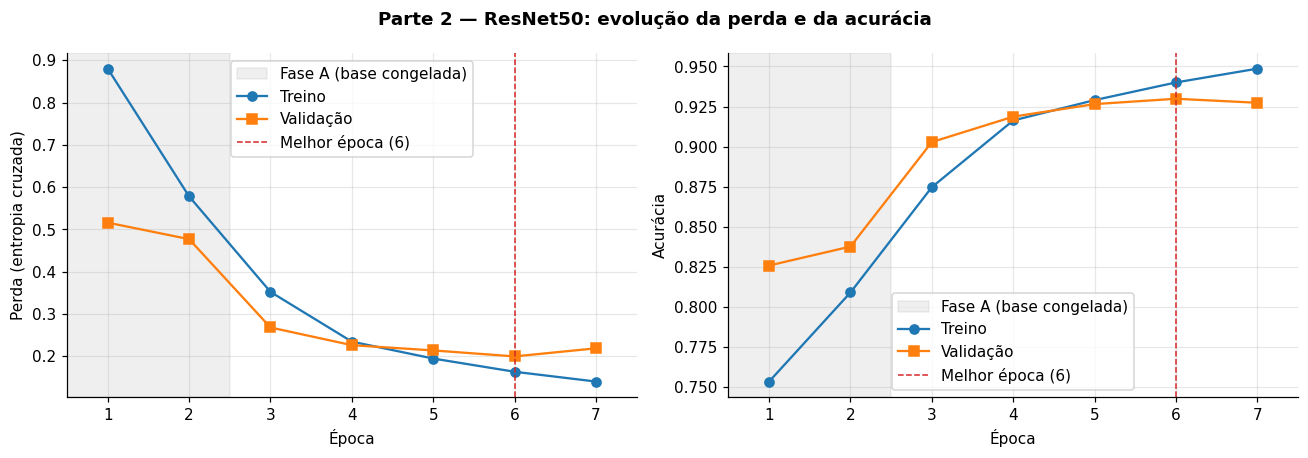

ResNet50: acurácia no teste 92.14% (± 0.53%) | perda 0.2241 | 23,608,202 parâmetros | 90.06 MB | 1.613 ms por imagem

              precision    recall  f1-score   support

 T-shirt/top      0.895     0.847     0.871      1000
      Calças      0.987     0.994     0.991      1000
    Camisola      0.937     0.819     0.874      1000
     Vestido      0.921     0.939     0.930      1000
      Casaco      0.819     0.935     0.873      1000
    Sandália      0.989     0.983     0.986      1000
      Camisa      0.766     0.775     0.770      1000
   Sapatilha      0.933     0.996     0.964      1000
        Mala      0.990     0.988     0.989      1000
       Botim      0.997     0.938     0.967      1000

    accuracy                          0.921     10000
   macro avg      0.923     0.921     0.921     10000
weighted avg      0.923     0.921     0.921     10000



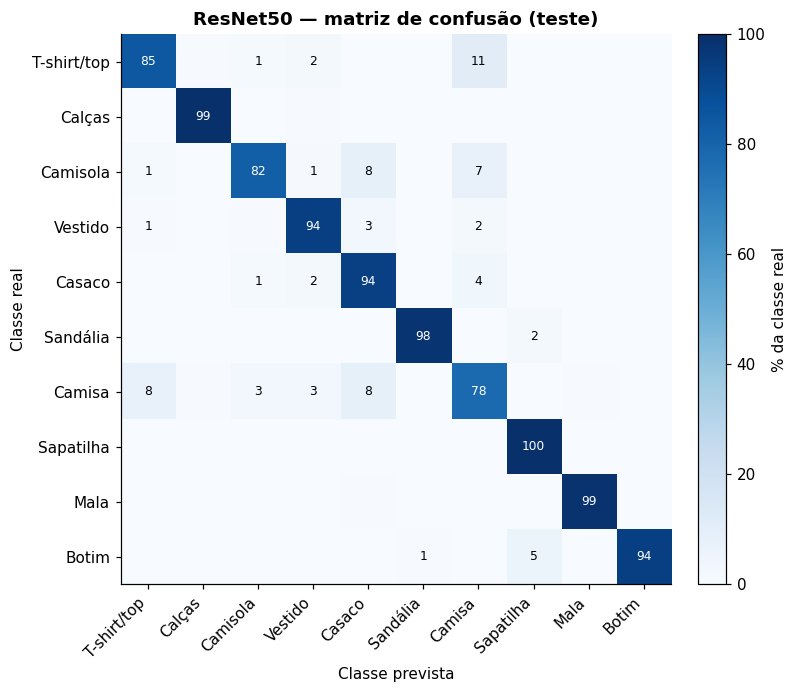

In [16]:
# 3.5 Curvas de treino e avaliação no conjunto de teste
grafico_treino(hist_resnet, "Parte 2 — ResNet50: evolução da perda e da acurácia",
               "05_resnet_curvas.png", fim_fase_a=len(hist_a["loss"]))
prev_resnet = avaliar("ResNet50", resnet, X_TESTE, y_teste, hist_resnet, tempo_resnet, tempos_resnet)
print()
print(classification_report(y_teste, prev_resnet, target_names=CLASSES, digits=3, zero_division=0))
grafico_confusao(y_teste, prev_resnet, "ResNet50 — matriz de confusão (teste)", "06_resnet_confusao.png")

In [17]:
# 3.6 ResNet50 vs. CNN simples
r, c = RESULTADOS["ResNet50"], RESULTADOS["CNN"]
comparacao = pd.DataFrame({
    "CNN": [f"{c['Acurácia (teste)']:.2%}", f"{c['Parâmetros']:,}", f"{c['Tamanho dos pesos (MB)']:.1f}",
            f"{c['Tempo de treino (s)']:.0f}", f"{c['Inferência (ms/imagem)']:.3f}"],
    "ResNet50": [f"{r['Acurácia (teste)']:.2%}", f"{r['Parâmetros']:,}", f"{r['Tamanho dos pesos (MB)']:.1f}",
                 f"{r['Tempo de treino (s)']:.0f}", f"{r['Inferência (ms/imagem)']:.3f}"],
    "ResNet50 / CNN": [f"{(r['Acurácia (teste)'] - c['Acurácia (teste)']) * 100:+.2f} p.p.",
                       f"{r['Parâmetros'] / c['Parâmetros']:.0f}×",
                       f"{r['Tamanho dos pesos (MB)'] / c['Tamanho dos pesos (MB)']:.0f}×",
                       f"{r['Tempo de treino (s)'] / c['Tempo de treino (s)']:.1f}×",
                       f"{r['Inferência (ms/imagem)'] / c['Inferência (ms/imagem)']:.1f}×"],
}, index=["Acurácia (teste)", "Parâmetros", "Tamanho dos pesos (MB)", "Tempo de treino (s)",
          "Inferência (ms/imagem)"])
display(comparacao)

,CNN,ResNet50,ResNet50 / CNN
Acurácia (teste),92.62%,92.14%,-0.48 p.p.
Parâmetros,"421,642","23,608,202",56×
Tamanho dos pesos (MB),1.6,90.1,56×
Tempo de treino (s),289,4538,15.7×
Inferência (ms/imagem),0.099,1.613,16.3×


**Resultado desta execução.** A ResNet50 ficou 0,48 p.p. abaixo da CNN (92,14 % contra 92,62 %), uma diferença dentro da margem de erro (≈ ±0,74 p.p.): na prática, as duas redes empatam. Mas a ResNet50 tem 56 vezes mais parâmetros e precisou de cerca de 16 vezes mais tempo, tanto no treino como na inferência.

**Como ler esta comparação.** Uma rede 56 vezes maior não ganha automaticamente a uma CNN pequena. Neste problema, há três fatores que jogam contra a ResNet50:
1. **Resolução:** a 32×32, a rede reduz a imagem 32 vezes e o último estágio trabalha sobre mapas de 1×1 — os filtros do ImageNet foram aprendidos para objetos vistos a 224×224.
2. **Domínio:** silhuetas de roupa em tons de cinzento, centradas e sem fundo, estão muito longe das fotografias a cores do ImageNet, por isso as características pré-treinadas transferem-se só em parte.
3. **Dados:** com 54 000 imagens de treino, uma CNN pequena já aprende o que precisa de raiz; o *transfer learning* dá mais vantagem quando há poucos dados rotulados.

A tabela da Parte 4 junta esta comparação com a das redes recorrentes.

## 4. Parte 3 — Rede Recorrente (LSTM e GRU)

Uma RNN processa uma sequência elemento a elemento e mantém um **estado interno** que resume o que já viu. Para a aplicar a imagens, cada imagem passa a ser uma sequência de **28 passos de tempo** (as linhas, de cima para baixo), cada um com **28 características** (os píxeis dessa linha). A rede lê a imagem como quem lê um texto: uma linha de cada vez, sem nunca ver a imagem inteira.

- **LSTM** — tem uma célula de memória controlada por três portas (esquecimento, entrada e saída), que decidem o que apagar, o que acrescentar e o que expor em cada passo. Resolve o problema do gradiente evanescente das RNN simples.
- **GRU** — versão simplificada, com duas portas (atualização e *reset*) e sem célula de memória separada: tem menos parâmetros e costuma treinar mais depressa, com resultados semelhantes.

O enunciado pede uma LSTM *ou* uma GRU; implemento as duas, com a mesma estrutura — `RNN(128 unidades) → Dropout(0,3) → Dense(10, Softmax)` —, em que só o último estado da sequência alimenta a classificação. Mesmo otimizador, lotes e paragem antecipada da CNN.

Formato para a RNN: (54000, 28, 28) = (imagens, linhas = passos de tempo, píxeis por linha)


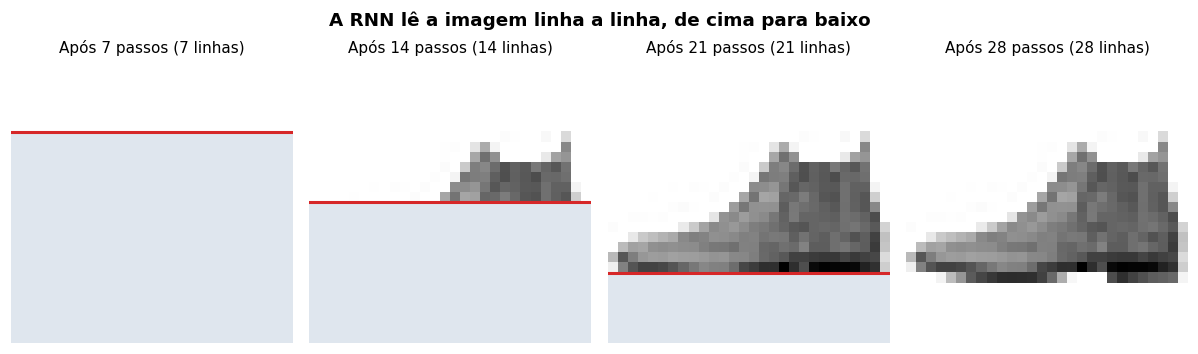

In [18]:
# =============================================================================
# 4.1  Da imagem à sequência
# =============================================================================
# (imagens, 28, 28, 1) -> (imagens, 28 passos de tempo, 28 características por passo)
X_TREINO_SEQ, X_VAL_SEQ, X_TESTE_SEQ = X_TREINO[..., 0], X_VAL[..., 0], X_TESTE[..., 0]
print("Formato para a RNN:", X_TREINO_SEQ.shape, "= (imagens, linhas = passos de tempo, píxeis por linha)")

# O que a RNN já "leu" da imagem ao fim de 7, 14, 21 e 28 passos
exemplo = X_TESTE_SEQ[indice]
mapa_cores = plt.get_cmap("gray_r").copy()
mapa_cores.set_bad("#dfe6ee")   # linhas ainda não lidas
fig, eixos = plt.subplots(1, 4, figsize=(11, 3.3))
for eixo, passos_lidos in zip(eixos, [7, 14, 21, 28]):
    parcial = np.full_like(exemplo, np.nan)
    parcial[:passos_lidos] = exemplo[:passos_lidos]
    eixo.imshow(parcial, cmap=mapa_cores, vmin=0, vmax=1)
    if passos_lidos < 28:
        eixo.axhline(passos_lidos - 0.5, color="tab:red", lw=2)
    eixo.set_title(f"Após {passos_lidos} passos ({passos_lidos} linhas)", fontsize=10)
    eixo.axis("off")
fig.suptitle("A RNN lê a imagem linha a linha, de cima para baixo", fontweight="bold")
fig.tight_layout()
fig.savefig(os.path.join(PASTA, "07_rnn_imagem_como_sequencia.png"), bbox_inches="tight")
plt.show()

In [19]:
# 4.2 LSTM
def criar_rnn(tipo, unidades=128):
    """RNN(unidades) -> Dropout -> Dense(10, Softmax); só o último estado alimenta a classificação."""
    camada_recorrente = {"LSTM": layers.LSTM, "GRU": layers.GRU}[tipo]
    return keras.Sequential([
        # None: aceita sequências de qualquer comprimento (usado na análise da secção 4.4)
        keras.Input(shape=(None, 28), name="linhas"),
        # Parâmetros por omissão de propósito: em GPU, o Keras usa a implementação cuDNN,
        # muito mais rápida; opções como recurrent_dropout desligam-na
        camada_recorrente(unidades, name=tipo.lower()),
        layers.Dropout(0.3, name="dropout"),
        layers.Dense(10, activation="softmax", name="saida"),
    ], name=tipo)


lstm = criar_rnn("LSTM")
lstm.compile(optimizer=keras.optimizers.Adam(1e-3), loss="sparse_categorical_crossentropy",
             metrics=["accuracy"])
lstm.summary()
hist_lstm, tempo_lstm, tempos_lstm = treinar(lstm, X_TREINO_SEQ, y_treino, X_VAL_SEQ, y_val,
                                             epocas=EPOCAS_MAX, lote=128)
print(f"\nTreino da LSTM: {tempo_lstm:.0f} s em {len(tempos_lstm)} épocas "
      f"({np.mean(tempos_lstm):.1f} s por época)")

Model: "LSTM"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 128)            │        80,384 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ saida (Dense)                   │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 81,674 (319.04 KB)

 Trainable params: 81,674 (319.04 KB)

 Non-trainable params: 0 (0.00 B)

...

Epoch 16/20


422/422 - 16s - 38ms/step - accuracy: 0.9048 - loss: 0.2570 - val_accuracy: 0.8977 - val_loss: 0.2850


Epoch 17/20


422/422 - 33s - 78ms/step - accuracy: 0.9058 - loss: 0.2506 - val_accuracy: 0.9003 - val_loss: 0.2880



Treino da LSTM: 229 s em 17 épocas (13.4 s por época)


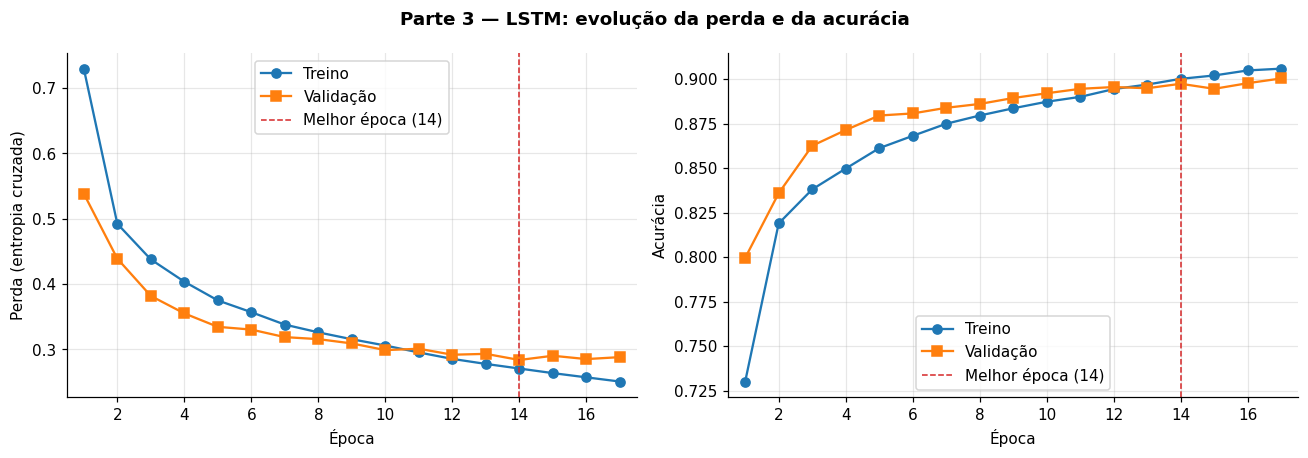

LSTM: acurácia no teste 88.45% (± 0.63%) | perda 0.3240 | 81,674 parâmetros | 0.31 MB | 0.156 ms por imagem

              precision    recall  f1-score   support

 T-shirt/top      0.809     0.841     0.825      1000
      Calças      0.983     0.967     0.975      1000
    Camisola      0.789     0.799     0.794      1000
     Vestido      0.875     0.899     0.887      1000
      Casaco      0.815     0.797     0.806      1000
    Sandália      0.974     0.967     0.970      1000
      Camisa      0.712     0.674     0.693      1000
   Sapatilha      0.935     0.972     0.953      1000
        Mala      0.976     0.978     0.977      1000
       Botim      0.973     0.951     0.962      1000

    accuracy                          0.884     10000
   macro avg      0.884     0.885     0.884     10000
weighted avg      0.884     0.884     0.884     10000



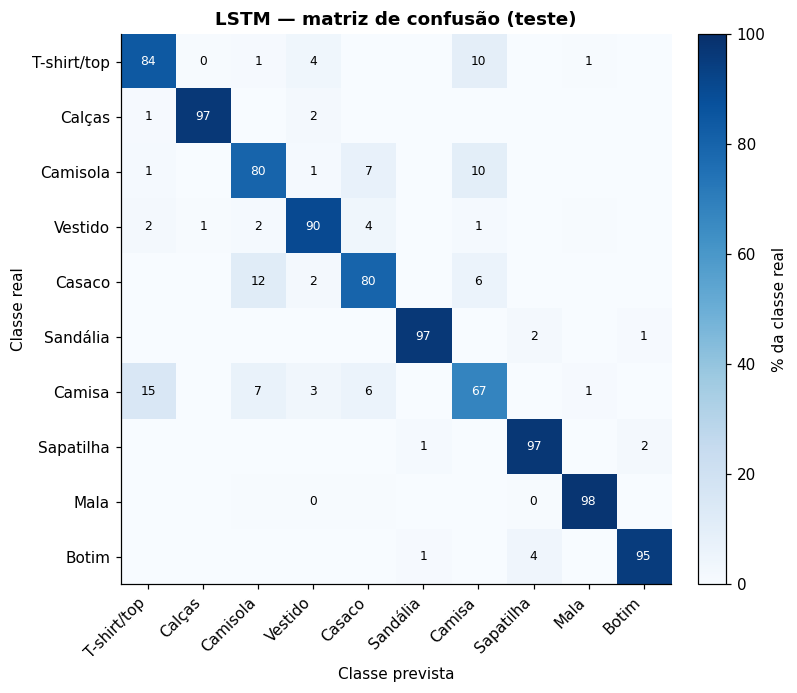

In [20]:
grafico_treino(hist_lstm, "Parte 3 — LSTM: evolução da perda e da acurácia", "08_lstm_curvas.png")
prev_lstm = avaliar("LSTM", lstm, X_TESTE_SEQ, y_teste, hist_lstm, tempo_lstm, tempos_lstm)
print()
print(classification_report(y_teste, prev_lstm, target_names=CLASSES, digits=3, zero_division=0))
grafico_confusao(y_teste, prev_lstm, "LSTM — matriz de confusão (teste)", "09_lstm_confusao.png")

In [21]:
# 4.3 GRU (mesma estrutura, célula recorrente diferente)
gru = criar_rnn("GRU")
gru.compile(optimizer=keras.optimizers.Adam(1e-3), loss="sparse_categorical_crossentropy",
            metrics=["accuracy"])
gru.summary()
hist_gru, tempo_gru, tempos_gru = treinar(gru, X_TREINO_SEQ, y_treino, X_VAL_SEQ, y_val,
                                          epocas=EPOCAS_MAX, lote=128)
print(f"\nTreino da GRU: {tempo_gru:.0f} s em {len(tempos_gru)} épocas "
      f"({np.mean(tempos_gru):.1f} s por época)")

Model: "GRU"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ gru (GRU)                       │ (None, 128)            │        60,672 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ saida (Dense)                   │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 61,962 (242.04 KB)

 Trainable params: 61,962 (242.04 KB)

 Non-trainable params: 0 (0.00 B)

...

Epoch 14/20


422/422 - 11s - 26ms/step - accuracy: 0.9007 - loss: 0.2657 - val_accuracy: 0.8975 - val_loss: 0.2817


Epoch 15/20


422/422 - 11s - 27ms/step - accuracy: 0.9031 - loss: 0.2579 - val_accuracy: 0.8958 - val_loss: 0.2842



Treino da GRU: 245 s em 15 épocas (16.3 s por época)


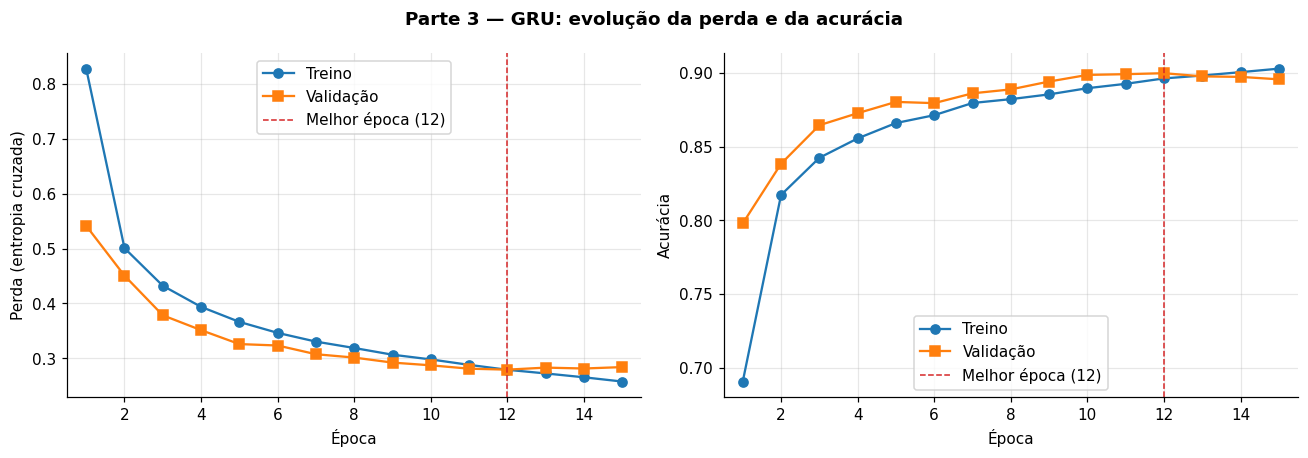

GRU: acurácia no teste 88.61% (± 0.62%) | perda 0.3151 | 61,962 parâmetros | 0.24 MB | 0.093 ms por imagem

              precision    recall  f1-score   support

 T-shirt/top      0.843     0.821     0.832      1000
      Calças      0.987     0.964     0.975      1000
    Camisola      0.813     0.797     0.805      1000
     Vestido      0.849     0.916     0.881      1000
      Casaco      0.815     0.803     0.809      1000
    Sandália      0.971     0.959     0.965      1000
      Camisa      0.709     0.708     0.708      1000
   Sapatilha      0.943     0.959     0.951      1000
        Mala      0.978     0.973     0.975      1000
       Botim      0.955     0.961     0.958      1000

    accuracy                          0.886     10000
   macro avg      0.886     0.886     0.886     10000
weighted avg      0.886     0.886     0.886     10000



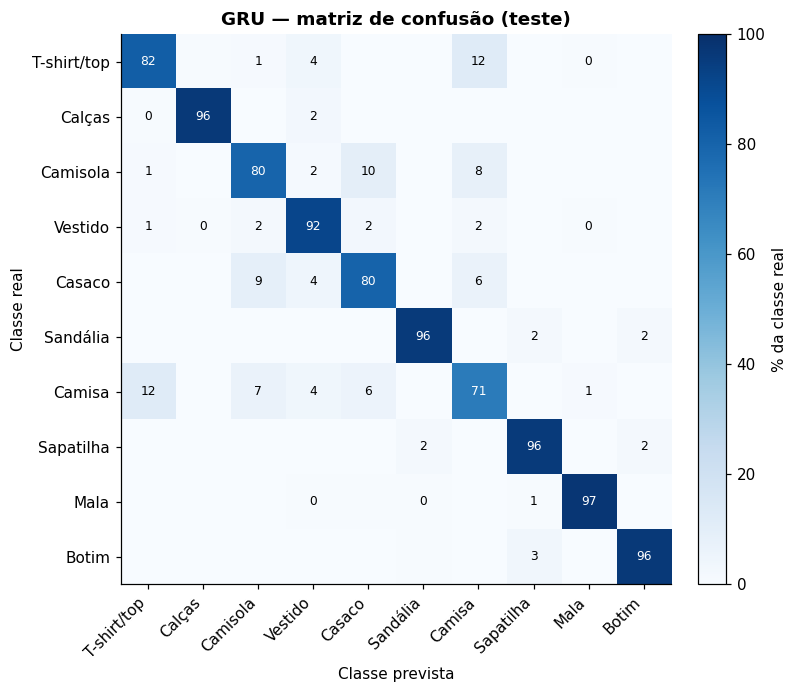

In [22]:
grafico_treino(hist_gru, "Parte 3 — GRU: evolução da perda e da acurácia", "10_gru_curvas.png")
prev_gru = avaliar("GRU", gru, X_TESTE_SEQ, y_teste, hist_gru, tempo_gru, tempos_gru)
print()
print(classification_report(y_teste, prev_gru, target_names=CLASSES, digits=3, zero_division=0))
grafico_confusao(y_teste, prev_gru, "GRU — matriz de confusão (teste)", "11_gru_confusao.png")

### 4.4 Quanto da imagem precisa a RNN de ler?
Como as redes aceitam sequências de qualquer comprimento, é possível pedir-lhes uma classificação a meio da leitura — dando-lhes só as primeiras *k* linhas de cada imagem de teste. As redes nunca foram treinadas para responder a meio da imagem, por isso a curva mostra quanta informação útil o estado interno já acumulou em cada ponto. É a diferença essencial em relação à CNN, que vê a imagem inteira de uma só vez.

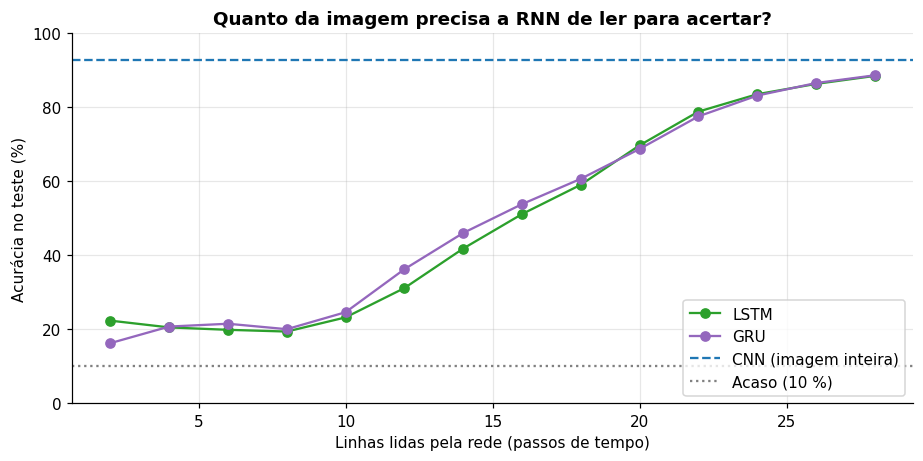

LSTM: com metade da imagem (14 linhas) acerta 41.8%; chega a 90 % da acurácia final ao fim de 24 linhas
GRU: com metade da imagem (14 linhas) acerta 46.0%; chega a 90 % da acurácia final ao fim de 24 linhas


In [23]:
# 4.4 Acurácia em função do número de linhas lidas
passos = list(range(2, 29, 2))
curvas_linhas = {}
for nome, modelo in [("LSTM", lstm), ("GRU", gru)]:
    curvas_linhas[nome] = [
        float(np.mean(modelo.predict(X_TESTE_SEQ[:, :k], batch_size=512, verbose=0).argmax(axis=1) == y_teste))
        for k in passos]

fig, eixo = plt.subplots(figsize=(8.5, 4.3))
for nome, acuracias in curvas_linhas.items():
    eixo.plot(passos, np.array(acuracias) * 100, "o-", color=CORES[nome], label=nome)
eixo.axhline(RESULTADOS["CNN"]["Acurácia (teste)"] * 100, color=CORES["CNN"], ls="--",
             label="CNN (imagem inteira)")
eixo.axhline(10, color="gray", ls=":", label="Acaso (10 %)")
eixo.set_xlabel("Linhas lidas pela rede (passos de tempo)")
eixo.set_ylabel("Acurácia no teste (%)")
eixo.set_ylim(0, 100)
eixo.set_title("Quanto da imagem precisa a RNN de ler para acertar?", fontweight="bold")
eixo.legend(loc="lower right")
fig.tight_layout()
fig.savefig(os.path.join(PASTA, "12_rnn_acuracia_por_linhas.png"), bbox_inches="tight")
plt.show()

for nome, acuracias in curvas_linhas.items():
    final = acuracias[-1]
    k90 = next(k for k, a in zip(passos, acuracias) if a >= 0.9 * final)
    print(f"{nome}: com metade da imagem (14 linhas) acerta {acuracias[passos.index(14)]:.1%}; "
          f"chega a 90 % da acurácia final ao fim de {k90} linhas")

## 5. Parte 4 — Comparação e análise

Os quatro modelos foram treinados na mesma máquina, com as mesmas partições e a mesma paragem antecipada. Métricas da tabela:
- **Acurácia e perda no teste** — 10 000 imagens nunca vistas no treino. O **IC 95 %** indica a incerteza estatística da acurácia de cada modelo (±0,5 a ±0,6 p.p. com 10 000 imagens). Para comparar dois modelos, a margem da diferença é maior, ≈ √(IC₁² + IC₂²), entre ±0,7 e ±0,9 p.p. conforme o par: diferenças menores do que isso não permitem concluir que um modelo é melhor do que outro. É o critério usado no resumo da secção 5.7.
- **Tempo de treino** — tempo de relógio total do `fit`, incluindo a validação no fim de cada época; na ResNet50 soma as duas fases.
- **Parâmetros e tamanho** — número de pesos e memória que ocupam em `float32` (4 bytes por parâmetro), ou seja, o tamanho do modelo guardado sem o estado do otimizador.
- **Inferência** — tempo médio por imagem ao classificar o conjunto de teste em lotes de 256.

⚠ Os tempos dependem do hardware (ver o dispositivo indicado na secção 0.2): só são comparáveis entre si dentro da mesma execução.

In [24]:
# =============================================================================
# 5.1  Tabela comparativa
# =============================================================================
modelos = list(RESULTADOS)
tabela = pd.DataFrame(RESULTADOS).T.astype(float)
tabela.index.name = "Modelo"
tabela["Treino (× CNN)"] = tabela["Tempo de treino (s)"] / tabela.loc["CNN", "Tempo de treino (s)"]
tabela["Tamanho (× CNN)"] = tabela["Tamanho dos pesos (MB)"] / tabela.loc["CNN", "Tamanho dos pesos (MB)"]
tabela.to_csv(os.path.join(PASTA, "tabela_comparativa.csv"))

formatos = {
    "Acurácia (teste)": "{:.2%}", "IC 95 % (±)": "{:.2%}", "Perda (teste)": "{:.4f}",
    "Épocas": "{:.0f}", "Tempo de treino (s)": "{:,.0f}", "Tempo médio por época (s)": "{:,.1f}",
    "Parâmetros": "{:,.0f}", "Parâmetros treináveis": "{:,.0f}", "Tamanho dos pesos (MB)": "{:.2f}",
    "Inferência (ms/imagem)": "{:.3f}", "Treino (× CNN)": "{:.1f}×", "Tamanho (× CNN)": "{:.1f}×",
}
print("Hardware:", DISPOSITIVO)
display(pd.DataFrame({coluna: tabela[coluna].map(formato.format) for coluna, formato in formatos.items()}).T)

Hardware: CPU (8 núcleos lógicos)


Modelo,CNN,ResNet50,LSTM,GRU
Acurácia (teste),92.62%,92.14%,88.45%,88.61%
IC 95 % (±),0.51%,0.53%,0.63%,0.62%
Perda (teste),0.2180,0.2241,0.3240,0.3151
Épocas,19,7,17,15
Tempo de treino (s),289,"4,538",229,245
Tempo médio por época (s),15.2,647.9,13.4,16.3
Parâmetros,"421,642","23,608,202","81,674","61,962"
Parâmetros treináveis,"421,642","23,501,962","81,674","61,962"
Tamanho dos pesos (MB),1.61,90.06,0.31,0.24
Inferência (ms/imagem),0.099,1.613,0.156,0.093


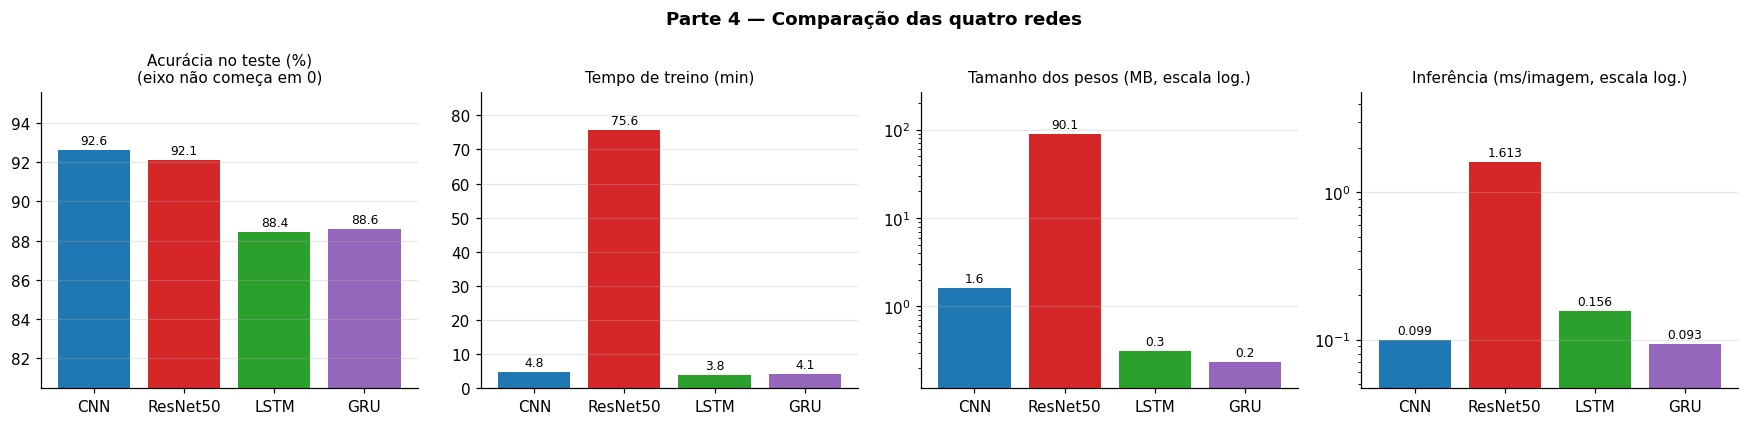

In [25]:
# 5.2 Métricas principais lado a lado
cores = [CORES[m] for m in modelos]
fig, eixos = plt.subplots(1, 4, figsize=(16, 3.9))
graficos = [
    ("Acurácia (teste)", 100, "Acurácia no teste (%)\n(eixo não começa em 0)", False, "{:.1f}"),
    ("Tempo de treino (s)", 1 / 60, "Tempo de treino (min)", False, "{:.1f}"),
    ("Tamanho dos pesos (MB)", 1, "Tamanho dos pesos (MB, escala log.)", True, "{:.1f}"),
    ("Inferência (ms/imagem)", 1, "Inferência (ms/imagem, escala log.)", True, "{:.3f}"),
]
for eixo, (metrica, escala, titulo, logaritmica, formato) in zip(eixos, graficos):
    valores = tabela.loc[modelos, metrica] * escala
    barras = eixo.bar(modelos, valores, color=cores)
    if logaritmica:
        eixo.set_yscale("log")
        eixo.set_ylim(valores.min() / 2, valores.max() * 3)
    elif metrica.startswith("Acurácia"):
        eixo.set_ylim(max(0, valores.min() - 8), min(100, valores.max() + 3))
    else:
        eixo.set_ylim(0, valores.max() * 1.15)
    eixo.bar_label(barras, labels=[formato.format(v) for v in valores], fontsize=8, padding=2)
    eixo.set_title(titulo, fontsize=10)
    eixo.grid(axis="x", visible=False)
fig.suptitle("Parte 4 — Comparação das quatro redes", fontweight="bold")
fig.tight_layout()
fig.savefig(os.path.join(PASTA, "13_comparacao_metricas.png"), bbox_inches="tight")
plt.show()

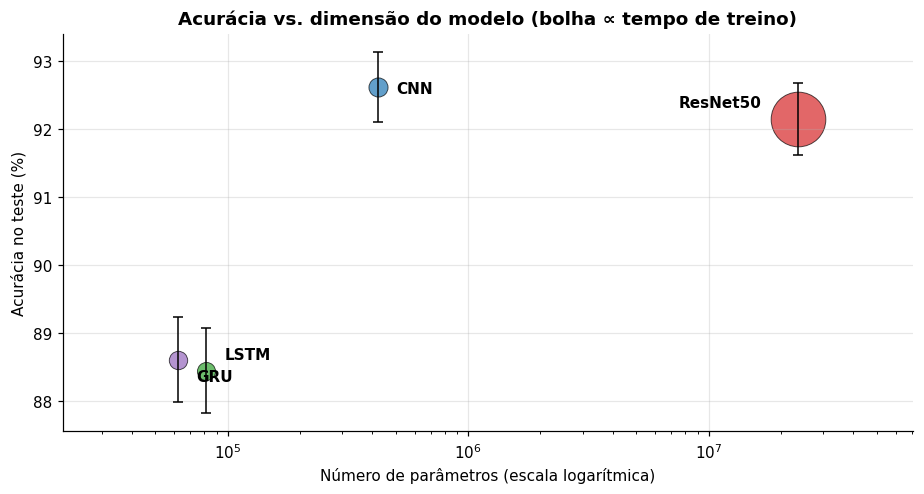

In [26]:
# 5.3 Acurácia vs. dimensão do modelo (a área de cada bolha é proporcional ao tempo de treino)
desvios = {"CNN": (12, -4), "ResNet50": (-78, 8), "LSTM": (12, 8), "GRU": (12, -14)}
fig, eixo = plt.subplots(figsize=(8.5, 4.6))
tempos_treino = tabela["Tempo de treino (s)"]
for m in modelos:
    x, y = tabela.loc[m, "Parâmetros"], tabela.loc[m, "Acurácia (teste)"] * 100
    eixo.scatter(x, y, s=80 + 1200 * tempos_treino[m] / tempos_treino.max(), color=CORES[m],
                 alpha=0.7, edgecolor="black", lw=0.6)
    eixo.errorbar(x, y, yerr=tabela.loc[m, "IC 95 % (±)"] * 100, color="black", lw=1, capsize=3)
    eixo.annotate(m, (x, y), xytext=desvios.get(m, (10, 0)), textcoords="offset points",
                  fontsize=10, fontweight="bold")
eixo.set_xscale("log")
eixo.set_xlim(tabela["Parâmetros"].min() / 3, tabela["Parâmetros"].max() * 3)
eixo.set_xlabel("Número de parâmetros (escala logarítmica)")
eixo.set_ylabel("Acurácia no teste (%)")
eixo.set_title("Acurácia vs. dimensão do modelo (bolha ∝ tempo de treino)", fontweight="bold")
fig.tight_layout()
fig.savefig(os.path.join(PASTA, "14_acuracia_vs_parametros.png"), bbox_inches="tight")
plt.show()

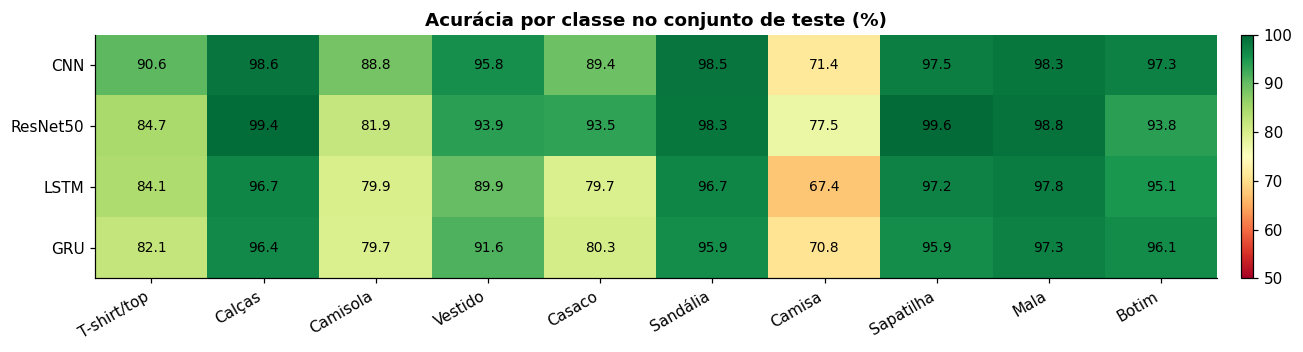

CNN: classe mais difícil = Camisa (71.4 %)
ResNet50: classe mais difícil = Camisa (77.5 %)
LSTM: classe mais difícil = Camisa (67.4 %)
GRU: classe mais difícil = Camisa (70.8 %)


In [27]:
# 5.4 Acurácia por classe: onde é que cada arquitetura falha?
por_classe = pd.DataFrame(
    {m: [np.mean(PREVISOES[m][y_teste == c] == c) * 100 for c in range(10)] for m in modelos},
    index=CLASSES).T
fig, eixo = plt.subplots(figsize=(12, 3.3))
imagem = eixo.imshow(por_classe.values, cmap="RdYlGn", vmin=50, vmax=100, aspect="auto")
eixo.set_xticks(range(10), CLASSES, rotation=30, ha="right")
eixo.set_yticks(range(len(modelos)), modelos)
for i in range(len(modelos)):
    for j in range(10):
        eixo.text(j, i, f"{por_classe.values[i, j]:.1f}", ha="center", va="center", fontsize=9)
eixo.grid(False)
eixo.set_title("Acurácia por classe no conjunto de teste (%)", fontweight="bold")
fig.colorbar(imagem, ax=eixo, fraction=0.025, pad=0.02)
fig.tight_layout()
fig.savefig(os.path.join(PASTA, "15_acuracia_por_classe.png"), bbox_inches="tight")
plt.show()
for m in modelos:
    print(f"{m}: classe mais difícil = {por_classe.loc[m].idxmin()} ({por_classe.loc[m].min():.1f} %)")

349 imagens de teste (3.5%) são classificadas erradamente pelos quatro modelos.

Confusões mais frequentes entre essas imagens (classe real → previsão da CNN):
Camisa → T-shirt/top    56
Camisa → Casaco         36
T-shirt/top → Camisa    30
Camisola → Camisa       24
Camisola → Casaco       24


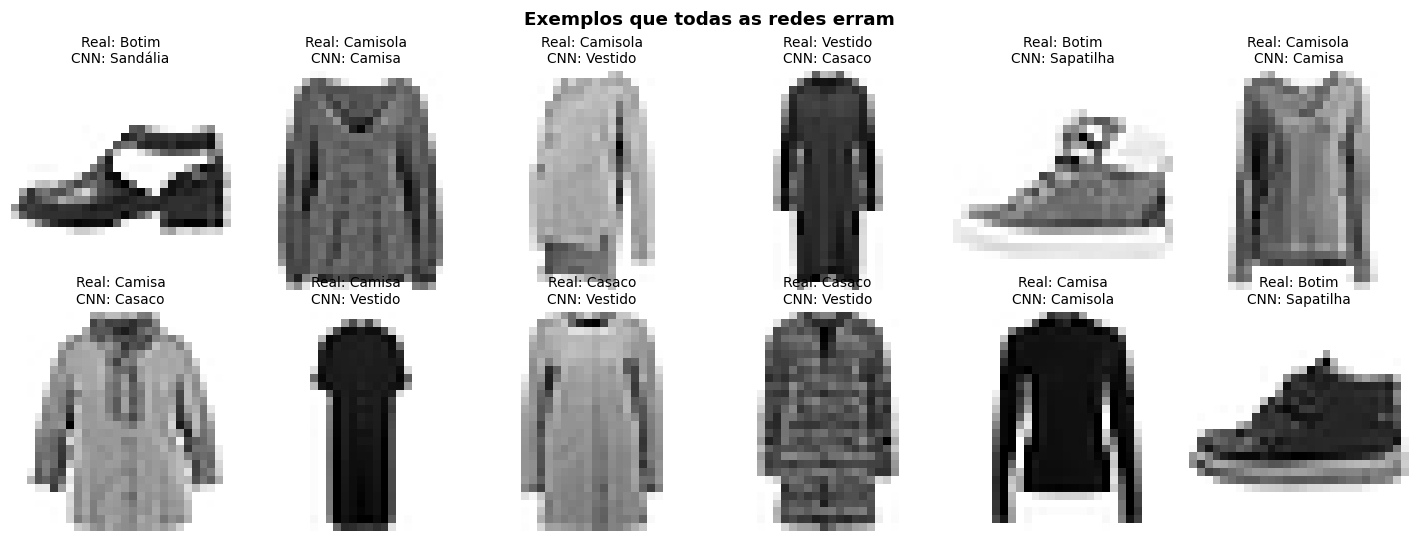

In [28]:
# 5.5 Imagens que nenhuma das quatro redes acerta
erros_de_todos = np.flatnonzero(np.all([PREVISOES[m] != y_teste for m in modelos], axis=0))
print(f"{len(erros_de_todos)} imagens de teste ({len(erros_de_todos) / len(y_teste):.1%}) "
      "são classificadas erradamente pelos quatro modelos.")
confusoes = pd.Series([f"{CLASSES[y_teste[i]]} → {CLASSES[PREVISOES['CNN'][i]]}"
                       for i in erros_de_todos]).value_counts().head(5)
print("\nConfusões mais frequentes entre essas imagens (classe real → previsão da CNN):")
print(confusoes.to_string())

fig, eixos = plt.subplots(2, 6, figsize=(13, 5))
for k, eixo in enumerate(eixos.flat):
    eixo.axis("off")
    if k < len(erros_de_todos):
        i = erros_de_todos[k]
        eixo.imshow(X_TESTE[i, ..., 0], cmap="gray_r")
        eixo.set_title(f"Real: {CLASSES[y_teste[i]]}\nCNN: {CLASSES[PREVISOES['CNN'][i]]}", fontsize=9)
fig.suptitle("Exemplos que todas as redes erram", fontweight="bold")
fig.tight_layout()
fig.savefig(os.path.join(PASTA, "16_exemplos_dificeis.png"), bbox_inches="tight")
plt.show()

### 5.6 Em que contextos cada arquitetura é mais vantajosa?

**CNN simples — imagens pequenas e recursos limitados**
- Imagens de baixa resolução, com fundo e enquadramento pouco variáveis: documentos digitalizados, ícones, peças fotografadas numa linha de produção com câmara fixa, imagens de sensores.
- Dispositivos com pouca memória ou sem GPU (telemóveis, microcontroladores, câmaras inteligentes): poucos parâmetros, pesos de 1 a 2 MB e inferência rápida em CPU.
- Domínios muito diferentes das fotografias naturais (espectrogramas de áudio, imagens médicas em tons de cinzento, radar), quando há dados rotulados suficientes para treinar de raiz.
- Como primeira *baseline*: treina em minutos e mostra se vale a pena investir numa rede maior.

**ResNet pré-treinada (*transfer learning*) — poucos dados e imagens "naturais"**
- Poucas imagens rotuladas (de centenas a alguns milhares): as características aprendidas no ImageNet compensam a falta de dados — é o cenário para que o *transfer learning* foi pensado.
- Fotografias a cores de resolução média ou alta (a partir de ~96–224 píxeis), com objetos, texturas e fundos variados: é aí que a profundidade e o campo recetivo grande fazem diferença.
- Tarefas difíceis: muitas classes, distinções finas (espécies, defeitos subtis) ou como *backbone* de deteção e segmentação (Faster R-CNN, Mask R-CNN, U-Net com codificador ResNet).
- Quando há GPU para treinar e o custo de ~90 MB de pesos e de maior latência é aceitável (servidor ou nuvem).
- Neste trabalho, esteve fora do seu terreno: imagens 28×28 em tons de cinzento, ampliadas para 32×32. Mesmo com a afinação da base inteira, só empatou com a CNN (92,14 % contra 92,62 %), a um custo de cerca de 16 vezes mais tempo de treino.

**RNN (LSTM/GRU) — dados que são sequências**
- Dados sequenciais por natureza: texto, fala e áudio, séries temporais (sensores, consumos, preços), sinais biomédicos (ECG), registos de eventos.
- Em visão, faz sentido quando a imagem esconde uma sequência: reconhecimento de texto manuscrito ou de matrículas (arquitetura CRNN — uma CNN extrai características e uma LSTM lê-as da esquerda para a direita), vídeo (uma CNN por frame e uma LSTM ao longo do tempo) ou geração de legendas para imagens.
- Como classificador isolado de imagens estáticas, não é a escolha certa: vê uma linha de cada vez e tem de guardar tudo no estado interno; partilha pesos entre linhas, mas não ao longo de cada linha (um padrão deslocado alguns píxeis para o lado chega à rede por pesos diferentes); e o treino é sequencial, logo difícil de paralelizar.
- GRU ou LSTM: a GRU tem cerca de 25 % menos parâmetros e costuma treinar mais depressa com resultados semelhantes; a LSTM pode compensar em dependências muito longas. Nesta execução, as duas empataram em acurácia (88,61 % e 88,45 %), mas, em CPU, a GRU não foi mais rápida a treinar.

In [29]:
# 5.7 Resumo automático dos resultados desta execução
acc = tabela["Acurácia (teste)"]
ic = tabela["IC 95 % (±)"]
mais_precisa = acc.idxmax()
rnn_melhor = acc[["LSTM", "GRU"]].idxmax()


def diferenca_texto(a, b):
    """Diferença de acurácia entre dois modelos, indicando se é estatisticamente clara."""
    d = (acc[a] - acc[b]) * 100
    margem = np.sqrt(ic[a] ** 2 + ic[b] ** 2) * 100   # margem aproximada da diferença (IC 95 %)
    return f"{d:+.2f} p.p. ({'diferença clara' if abs(d) > margem else 'dentro da margem de erro'})"


resumo = [
    f"Modelo mais preciso: {mais_precisa} ({acc[mais_precisa]:.2%} ± {ic[mais_precisa]:.2%}).",
    f"ResNet50 vs. CNN: {diferenca_texto('ResNet50', 'CNN')}, com "
    f"{tabela.loc['ResNet50', 'Parâmetros'] / tabela.loc['CNN', 'Parâmetros']:.0f}× mais parâmetros, "
    f"{tabela.loc['ResNet50', 'Tamanho (× CNN)']:.0f}× o tamanho e "
    f"{tabela.loc['ResNet50', 'Treino (× CNN)']:.1f}× o tempo de treino da CNN.",
    f"Melhor RNN ({rnn_melhor}) vs. CNN: {diferenca_texto(rnn_melhor, 'CNN')}.",
    f"LSTM vs. GRU: {diferenca_texto('LSTM', 'GRU')}; a GRU tem "
    f"{1 - tabela.loc['GRU', 'Parâmetros'] / tabela.loc['LSTM', 'Parâmetros']:.0%} menos parâmetros.",
    f"Tempo total do notebook: {(time.perf_counter() - INICIO_NOTEBOOK) / 60:.1f} min em {DISPOSITIVO}.",
]
print("\n".join("• " + linha for linha in resumo))

• Modelo mais preciso: CNN (92.62% ± 0.51%).
• ResNet50 vs. CNN: -0.48 p.p. (dentro da margem de erro), com 56× mais parâmetros, 56× o tamanho e 15.7× o tempo de treino da CNN.
• Melhor RNN (GRU) vs. CNN: -4.01 p.p. (diferença clara).
• LSTM vs. GRU: -0.16 p.p. (dentro da margem de erro); a GRU tem 24% menos parâmetros.
• Tempo total do notebook: 89.2 min em CPU (8 núcleos lógicos).


In [30]:
# 5.8 Guardar todos os resultados num ficheiro JSON (base do relatório em PDF)
resultados = {
    "ambiente": {"dispositivo": DISPOSITIVO, "sistema": f"{platform.system()} {platform.release()}",
                 "python": platform.python_version(), "tensorflow": tf.__version__,
                 "keras": keras.__version__, "modo_rapido": MODO_RAPIDO},
    "metricas": {m: {k: float(v) for k, v in RESULTADOS[m].items()} for m in modelos},
    "historicos": {m: {k: [float(x) for x in v] for k, v in HISTORICOS[m].items()} for m in modelos},
    "tempos_por_epoca": {"CNN": tempos_cnn, "ResNet50": tempos_resnet, "LSTM": tempos_lstm, "GRU": tempos_gru},
    "resnet": {"tamanho_entrada": TAMANHO_RESNET, "epocas_fase_a": len(hist_a["loss"]),
               "epocas_fase_b": len(hist_b["loss"]), "tempo_fase_a": tempo_a, "tempo_fase_b": tempo_b,
               "afinacao": INICIO_AFINACAO or "toda a base"},
    "acuracia_por_classe": por_classe.round(2).to_dict(orient="index"),
    "acuracia_por_linhas": {"passos": passos, **curvas_linhas},
    "erros_de_todos": int(len(erros_de_todos)),
    "confusoes_frequentes": confusoes.to_dict(),
    "resumo": resumo,
    "tempo_total_min": (time.perf_counter() - INICIO_NOTEBOOK) / 60,
}
with open(os.path.join(PASTA, "resultados.json"), "w", encoding="utf-8") as ficheiro:
    json.dump(resultados, ficheiro, ensure_ascii=False, indent=2)
print("Resultados guardados em", os.path.join(PASTA, "resultados.json"))
print("Figuras:", ", ".join(sorted(f for f in os.listdir(PASTA) if f.endswith(".png"))))

Resultados guardados em resultados_tarefa3\resultados.json
Figuras: 01_exemplos.png, 02_cnn_curvas.png, 03_cnn_confusao.png, 04_cnn_mapas_ativacao.png, 05_resnet_curvas.png, 06_resnet_confusao.png, 07_rnn_imagem_como_sequencia.png, 08_lstm_curvas.png, 09_lstm_confusao.png, 10_gru_curvas.png, 11_gru_confusao.png, 12_rnn_acuracia_por_linhas.png, 13_comparacao_metricas.png, 14_acuracia_vs_parametros.png, 15_acuracia_por_classe.png, 16_exemplos_dificeis.png


## 6. Conclusões

1. **A estrutura da rede pesa mais do que o tamanho.** A CNN simples aproveita duas propriedades das imagens — a localidade dos padrões e a partilha de pesos entre posições — e, com 421 642 parâmetros e menos de 5 minutos de treino em CPU, foi a mais precisa (92,62 %) e a que oferece o melhor equilíbrio entre acurácia e custo neste problema.
2. **O *transfer learning* depende da proximidade entre domínios.** A ResNet50 traz características aprendidas em fotografias a cores de 224×224; aplicadas a silhuetas cinzentas de 32×32, transferem-se só em parte (83,8 % de acurácia de validação com a base congelada), e a afinação da base inteira é o que as adapta (93,0 % na melhor época). O resultado final empata com o da CNN (−0,48 p.p., dentro da margem de erro), com 56 vezes mais parâmetros e cerca de 16 vezes mais tempo de treino.
3. **Uma RNN consegue classificar imagens, mas não é a ferramenta natural para isso.** A LSTM (88,45 %) e a GRU (88,61 %) ficam cerca de 4 p.p. abaixo da CNN — ao nível da MLP da Tarefa 2 (89,16 %), que também ignora a estrutura espacial. Leem a imagem linha a linha e a sua acurácia vai crescendo à medida que leem mais linhas (secção 4.4), enquanto a CNN vê a imagem inteira de uma vez; além disso, não têm a partilha de pesos ao longo de cada linha que a convolução dá de graça. As RNN brilham quando os dados são sequências — ou em arquiteturas híbridas CNN + RNN.
4. **A acurácia sozinha não chega para escolher um modelo.** Tamanho, tempo de treino e latência de inferência decidem o que é viável em produção; e diferenças de acurácia dentro da margem de erro (IC 95 %) não justificam trocar uma rede pequena por uma dezenas de vezes maior.

**Limitações e próximos passos**
- Uma única execução por modelo: repetir com várias sementes daria intervalos de confiança mais sólidos para as diferenças pequenas.
- Sem *data augmentation*: pequenas rotações e deslocações costumam melhorar a CNN e a ResNet.
- A ResNet50 foi usada a 32×32 por limitações de CPU; com GPU, uma resolução de 64–96 píxeis deverá aproximar mais as características do ImageNet.
- Uma arquitetura híbrida CNN + LSTM (ou um *Vision Transformer*) seria o passo natural para explorar a leitura sequencial sem perder a informação espacial.